# 03 - Fine-tune XLM-R large (`xlm-roberta-large`) cho Extractive QA (UIT-ViQuAD 2.0)

## 0. Mục tiêu và cấu hình

Mục tiêu: so sánh với xlm-roberta-base (notebook 02: dev F1 59.9 @thr -1.0, NoAns acc 56.8; HasAns F1 ép trả lời 78.45) để xem model lớn có phân biệt NoAns tốt hơn không. Cụ thể: fine-tune `xlm-roberta-large` (lr 1.5e-5, per-device batch 16 x grad_accum 2 = 32) trên split `train` đã làm sạch (SQuAD-2.0 style, có câu hỏi không trả lời được), chọn `eval_loss` tốt nhất theo epoch, sau đó tune null threshold trên `dev`. Split `test` (= validation gốc) **không** được chạm tới ở notebook này; nó chỉ được chấm một lần ở notebook 04.

Cấu hình bên dưới lấy từ `src.train_qa.CFG`.

In [1]:
from pathlib import Path
import sys

# Colab: src/ and split_ids.json are uploaded to /content; local: project root (notebook lives in notebooks/)
if Path('/content').exists():
    ROOT = Path('/content')
elif Path.cwd().name == 'notebooks':
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src.train_qa import CFG as _CFG

CFG = dict(_CFG, model_name='xlm-roberta-large', lr=1.5e-5, train_bs=16, grad_accum=2, out_dir=str(ROOT / 'outputs' / 'xlmr_large'))
pd.DataFrame({'value': CFG}).astype(str)

| value                                                                         
---|---                                                                         
model_name | xlm-roberta-large                                                  
max_length | 384                                                                
doc_stride | 128                                                                
lr | 1.5e-05                                                                    
epochs | 3                                                                      
train_bs | 16                                                                   
eval_bs | 64                                                                    
grad_accum | 2                                                                  
warmup_ratio | 0.1                                                              
weight_decay | 0.01                                                             
seed | 42                   

## 1. Môi trường

In [2]:
import platform, torch, transformers, datasets

print('python      :', platform.python_version())
print('torch       :', torch.__version__)
print('transformers:', transformers.__version__)
print('datasets    :', datasets.__version__)
print('ROOT        :', ROOT)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f'GPU         : {p.name}, {p.total_memory / 1e9:.1f} GB, bf16 supported = {torch.cuda.is_bf16_supported()}')
else:
    print('GPU         : none (CPU only, training will be very slow)')

import src.data_clean, src.preprocess, src.postprocess, src.metrics, src.train_qa
print('src/ imports OK:', Path(src.train_qa.__file__).parent)

python      : 3.13.16
torch       : 2.14.1+cu130
transformers: 5.22.1
datasets    : 4.8.5
ROOT        : /content
GPU         : NVIDIA A100-SXM4-40GB, 42.4 GB, bf16 supported = True
src/ imports OK: /content/src


## 2. Dữ liệu

`get_data` đọc `data/processed/uit_viquad2_split` nếu có; nếu không (Colab) thì tải `taidng/UIT-ViQuAD2.0`, làm sạch bằng `data_clean.clean_split` rồi tách train/dev theo `split_ids.json`.

In [3]:
from src.train_qa import get_data, build_features
from IPython.display import Markdown, display

ds = get_data(ROOT)
rows = []
for k in ('train', 'dev', 'test'):
    n_no = sum(ds[k]['is_impossible'])
    rows.append({'split': k, 'examples': len(ds[k]), 'NoAns': n_no, 'NoAns %': round(100 * n_no / len(ds[k]), 2)})
sizes = pd.DataFrame(rows).set_index('split')
display(sizes)
display(Markdown(
    f"Train có {sizes.loc['train', 'examples']:,} ví dụ với {sizes.loc['train', 'NoAns %']}% NoAns, "
    f"dev {sizes.loc['dev', 'examples']:,} ví dụ ({sizes.loc['dev', 'NoAns %']}% NoAns, tách theo title nên không rò rỉ bài viết sang train), "
    f"test {sizes.loc['test', 'examples']:,} ví dụ ({sizes.loc['test', 'NoAns %']}% NoAns)."))

| examples | NoAns | NoAns %                                                    
---|---|---|---                                                                 
split |  |  |                                                                   
train | 25542 | 8262 | 32.35                                                    
dev | 2912 | 954 | 32.76                                                        
test | 3814 | 1161 | 30.44                                                      
Train có 25,542 ví dụ với 32.35% NoAns, dev 2,912 ví dụ (32.76% NoAns, tách theo
title nên không rò rỉ bài viết sang train), test 3,814 ví dụ (30.44% NoAns).    


## 3. Tokenize (sliding window)

Context dài hơn `max_length` được cắt thành nhiều window (`doc_stride` chồng lấp). Window không chứa đáp án được gán nhãn `[CLS]` (null).

In [4]:
from transformers import AutoTokenizer

EDA_WINDOWS_PER_EX = 1.068  # estimate from notebook 01 (EDA)
tok = AutoTokenizer.from_pretrained(CFG['model_name'])
feats = build_features(ds, tok, CFG, CFG['max_train'], CFG['max_dev'])
train_f, dev_loss_f, dev_eval_f, dev_ex = feats
n_tr, n_dv = CFG['max_train'] or len(ds['train']), len(dev_ex)
w_tr, w_dv = len(train_f) / n_tr, len(dev_eval_f) / n_dv
display(pd.DataFrame({'examples': [n_tr, n_dv], 'windows': [len(train_f), len(dev_eval_f)],
                      'windows/example': [round(w_tr, 3), round(w_dv, 3)]}, index=['train', 'dev']))
display(Markdown(
    f"Trung bình {w_tr:.3f} window/ví dụ ở train và {w_dv:.3f} ở dev, so với ước lượng EDA {EDA_WINDOWS_PER_EX} "
    f"(chênh {w_tr - EDA_WINDOWS_PER_EX:+.3f}). Ước lượng EDA tính theo token đếm trước nên sai khác nhỏ là bình thường; "
    f"số window thực là {len(train_f):,} cho một epoch."))

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]
tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]
sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]
tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]
Map:   0%|          | 0/2912 [00:00<?, ? examples/s]
windows: train 27324 from 25542 examples (1.070/ex), dev 3075 from 2912 examples (1.056/ex)
| examples | windows | windows/example                                          
---|---|---|---                                                                 
train | 25542 | 27324 | 1.070                                                   
dev | 2912 | 3075 | 1.056                                                       
Trung bình 1.070 window/ví dụ ở train và 1.056 ở dev, so với ước lượng EDA 1.068
(chênh +0.002). Ước lượng EDA tính theo token đếm trước nên sai khác nhỏ là bình
thường; số window thực là 27,324 cho một epoch.                                 


## 4. Huấn luyện

`run(CFG, ds=ds, feats=feats)` train với HF `Trainer` (eval/save theo epoch, `load_best_model_at_end` theo `eval_loss`), chấm dev, và lưu `model/`, `dev_threshold.json`, `train_summary.json` vào `out_dir`. Cell này chạy lâu nhất.

In [5]:
import time
from src.train_qa import run

t0 = time.time()
summary = run(CFG, ds=ds, feats=feats)
print(f'done in {(time.time() - t0) / 60:.1f} min (train_runtime {summary["train_runtime_s"]:.0f}s)')

device: {'name': 'NVIDIA A100-SXM4-40GB', 'total_memory_gb': 42.405855232}
model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB        
model.safetensors: downloading bytes:           |  0.00B            
Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]
[transformers] XLMRobertaForQuestionAnswering LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
qa_outputs.weight           | MISSING    | 
qa_outputs.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were ne

## 5. Đường cong học

Train loss cuối 0.696 (từ 5.609). Eval loss theo epoch: 0.988, 0.921, 0.920; tốt
nhất 0.920 tại step 2562 (checkpoint này được load lại). Eval loss giảm đều,    
chưa thấy overfit.                                                              


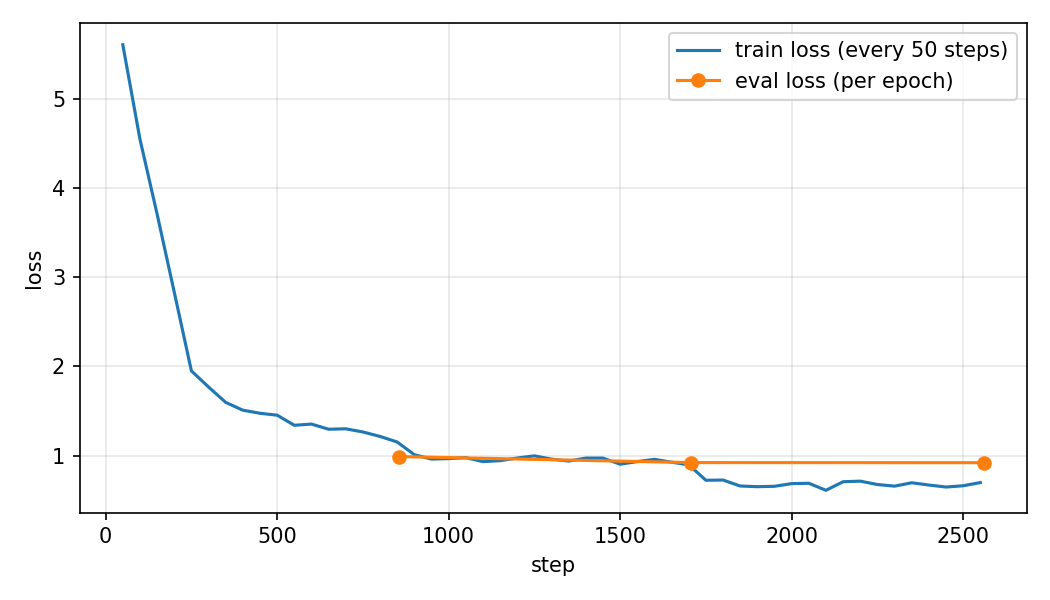

In [6]:
import matplotlib
import matplotlib.pyplot as plt

OUT = Path(CFG['out_dir'])
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
hist = summary['log_history']
tr = [(h['step'], h['loss']) for h in hist if 'loss' in h]
ev = [(h['step'], h['eval_loss']) for h in hist if 'eval_loss' in h]
fig, ax = plt.subplots(figsize=(7, 4))
if tr:
    ax.plot(*zip(*tr), label='train loss (every 50 steps)')
if ev:
    ax.plot(*zip(*ev), 'o-', label='eval loss (per epoch)')
ax.set_xlabel('step'); ax.set_ylabel('loss'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'learning_curves.png', dpi=150); plt.close(fig)

best_ev = min(ev, key=lambda x: x[1]) if ev else None
txt = f"Train loss cuối {tr[-1][1]:.3f} (từ {tr[0][1]:.3f}). " if tr else "Không có train loss được log. "
if ev:
    ev_s = ', '.join(f'{v:.3f}' for _, v in ev)
    verdict = ('Eval loss tăng ở epoch cuối so với tốt nhất, dấu hiệu overfit nhẹ.' if ev[-1][1] > best_ev[1]
               else 'Eval loss giảm đều, chưa thấy overfit.')
    txt += f"Eval loss theo epoch: {ev_s}; tốt nhất {best_ev[1]:.3f} tại step {best_ev[0]} (checkpoint này được load lại). {verdict}"
display(Markdown(txt))

## 6. Đánh giá dev và chọn ngưỡng

Quyết định NoAns: trả lời rỗng khi `null_score - best_span_score > threshold`. Ngưỡng được tune trên dev bằng cách tối đa hóa F1 tổng.

| threshold 0 | tuned (-0.63)                                                   
---|---|---                                                                     
EM | 62.47 | 62.84                                                              
F1 | 78.12 | 78.30                                                              
HasAns_F1 | 79.88 | 79.06                                                       
NoAns_acc | 74.53 | 76.73                                                       
Tune ngưỡng từ 0 lên -0.63 đổi F1 dev từ 78.12 thành 78.30 (+0.18), NoAns_acc từ
74.53 thành 76.73, HasAns_F1 từ 79.88 thành 79.06.                              

Lưu ý: ngưỡng được tune ngay trên dev nên điểm dev ở cột tuned là lạc quan      
(optimistic) và không so sánh trực tiếp được với điểm test (validation gốc).    
Split test chỉ được chấm một lần, với ngưỡng cố định này, ở notebook 04.        


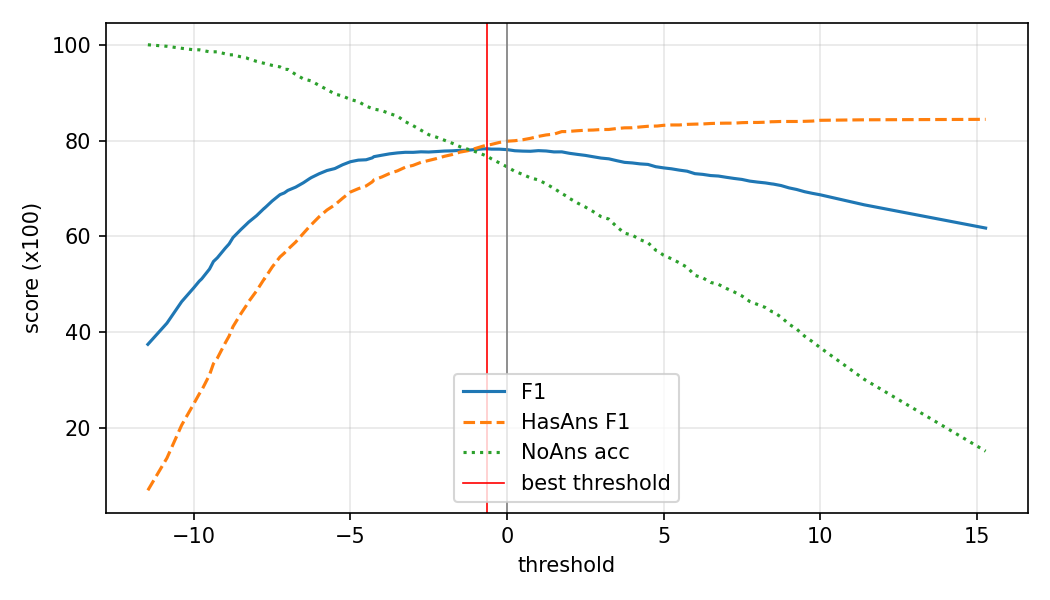

In [7]:
dev = summary['dev']
thr = pd.DataFrame(dev['table']).sort_values('threshold')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr['threshold'], thr['f1'], label='F1')
ax.plot(thr['threshold'], thr['HasAns_f1'], '--', label='HasAns F1')
ax.plot(thr['threshold'], thr['NoAns_acc'], ':', label='NoAns acc')
ax.axvline(0, color='gray', lw=.8); ax.axvline(dev['best_threshold'], color='r', lw=.8, label='best threshold')
ax.set_xlabel('threshold'); ax.set_ylabel('score (x100)'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'f1_vs_threshold.png', dpi=150); plt.close(fig)

m0, mb = dev['metrics_at_0'], dev['metrics_at_best']
cmp_ = pd.DataFrame({
    'threshold 0': [m0['exact'], m0['f1'], m0['HasAns_f1'], m0['NoAns_exact']],
    f"tuned ({dev['best_threshold']:.2f})": [mb['exact'], mb['f1'], mb['HasAns_f1'], mb['NoAns_exact']],
}, index=['EM', 'F1', 'HasAns_F1', 'NoAns_acc']).round(2)
display(cmp_)
display(Markdown(
    f"Tune ngưỡng từ 0 lên {dev['best_threshold']:.2f} đổi F1 dev từ {m0['f1']:.2f} thành {mb['f1']:.2f} "
    f"({mb['f1'] - m0['f1']:+.2f}), NoAns_acc từ {m0['NoAns_exact']:.2f} thành {mb['NoAns_exact']:.2f}, "
    f"HasAns_F1 từ {m0['HasAns_f1']:.2f} thành {mb['HasAns_f1']:.2f}.\n\n"
    "**Lưu ý:** ngưỡng được tune ngay trên dev nên điểm dev ở cột tuned là lạc quan (optimistic) và "
    "**không so sánh trực tiếp** được với điểm test (validation gốc). Split test chỉ được chấm một lần, với ngưỡng cố định này, ở notebook 04."))

## 7. Tài nguyên

In [8]:
RATE_UNITS_PER_HR = 6.73  # Colab compute units per hour, A100
rt = summary['train_runtime_s']
hours = rt / 3600
gpu = summary['gpu']
res = pd.DataFrame({'value': {
    'GPU': gpu['name'],
    'train_runtime (min)': round(rt / 60, 1),
    'samples/sec (windows)': round(summary['samples_per_sec'], 1),
    'peak GPU memory (GB)': None if summary['peak_mem_gb'] is None else round(summary['peak_mem_gb'], 2),
    'est. compute units': round(hours * RATE_UNITS_PER_HR, 2),
}})
display(res.astype(str))
display(Markdown(
    f"Huấn luyện mất {rt / 60:.1f} phút ({hours:.2f} giờ) trên {gpu['name']}, "
    f"~{summary['samples_per_sec']:.1f} window/s, peak memory {summary['peak_mem_gb'] or 0:.2f} GB "
    f"trên tổng {gpu['total_memory_gb'] or 0:.1f} GB. Ước tính {hours:.2f} h x {RATE_UNITS_PER_HR} = "
    f"**{hours * RATE_UNITS_PER_HR:.2f} compute units** (chỉ đúng nếu GPU là A100; chưa tính thời gian tải data/model và chấm dev)."))

| value                                                                         
---|---                                                                         
GPU | NVIDIA A100-SXM4-40GB                                                     
train_runtime (min) | 12.9                                                      
samples/sec (windows) | 105.6                                                   
peak GPU memory (GB) | 16.18                                                    
est. compute units | 1.45                                                       
Huấn luyện mất 12.9 phút (0.22 giờ) trên NVIDIA A100-SXM4-40GB, ~105.6 window/s,
peak memory 16.18 GB trên tổng 42.4 GB. Ước tính 0.22 h x 6.73 = 1.45 compute   
units (chỉ đúng nếu GPU là A100; chưa tính thời gian tải data/model và chấm     
dev).                                                                           


## 8. Lưu artifact

In [9]:
import tarfile

files = sorted(p for p in (OUT / 'model').rglob('*') if p.is_file())
display(pd.DataFrame({'file': [str(p.relative_to(OUT)) for p in files],
                      'MB': [round(p.stat().st_size / 1e6, 2) for p in files]}))
tar_path = OUT / 'out.tar'
with tarfile.open(tar_path, 'w') as tf:
    tf.add(OUT / 'model', arcname='model')
    for name in ('dev_threshold.json', 'train_summary.json'):
        tf.add(OUT / name, arcname=name)
print(f'{tar_path} ({tar_path.stat().st_size / 1e6:.0f} MB)')

| file | MB                                                                     
---|---|---                                                                     
0 | model/config.json | 0.00                                                    
1 | model/model.safetensors | 2235.42                                           
2 | model/tokenizer.json | 17.10                                                
3 | model/tokenizer_config.json | 0.00                                          
/content/outputs/xlmr_large/out.tar (2253 MB)


## Tải artifact về máy

Toàn bộ kết quả nằm trong một file `out.tar` (gồm `model/`, `dev_threshold.json`, `train_summary.json`). Tải về bằng Colab CLI (`colab download` đường dẫn `/content/outputs/xlmr_large/out.tar`) hoặc panel Files của Colab, rồi giải nén vào `outputs/xlmr_large/` trong project: `tar -xf out.tar -C outputs/xlmr_large`. Notebook 04 sẽ đọc `model/` và `dev_threshold.json` từ đó.

In [10]:
base = pd.DataFrame({
    'base thr0': [45.71, 59.58, 68.63, 40.99],
    'base tuned(-1.0)': [47.84, 59.90, 61.41, 56.81],
}, index=['EM', 'F1', 'HasAns_F1', 'NoAns_acc'])
d = summary['dev']; a0, ab = d['metrics_at_0'], d['metrics_at_best']
large = pd.DataFrame({
    'large thr0': [a0['exact'], a0['f1'], a0['HasAns_f1'], a0['NoAns_exact']],
    f"large tuned({d['best_threshold']:.2f})": [ab['exact'], ab['f1'], ab['HasAns_f1'], ab['NoAns_exact']],
}, index=base.index)
display(pd.concat([base, large], axis=1).round(2))
print(f"Tuned: large F1 {ab['f1']:.2f} vs base 59.90 ({ab['f1'] - 59.90:+.2f}); "
      f"NoAns_acc {ab['NoAns_exact']:.2f} vs base 56.81 ({ab['NoAns_exact'] - 56.81:+.2f}); "
      f"HasAns_F1 {ab['HasAns_f1']:.2f} vs base 61.41 ({ab['HasAns_f1'] - 61.41:+.2f}).")


| base thr0 | base tuned(-1.0) | large thr0 | large tuned(-0.63)                
---|---|---|---|---                                                             
EM | 45.71 | 47.84 | 62.47 | 62.84                                              
F1 | 59.58 | 59.90 | 78.12 | 78.30                                              
HasAns_F1 | 68.63 | 61.41 | 79.88 | 79.06                                       
NoAns_acc | 40.99 | 56.81 | 74.53 | 76.73                                       
Tuned: large F1 78.30 vs base 59.90 (+18.40); NoAns_acc 76.73 vs base 56.81 (+19.92); HasAns_F1 79.06 vs base 61.41 (+17.65).
